# 03. Autoencoder training and ablations
**Lead: Mayank.** Goal: understand and train the DL model before comparing models.

An **encoder** compresses the input; a **decoder** rebuilds it. A **bottleneck** is the small middle layer.
Our sizes are **29 -> 16 -> 8 -> 16 -> 29**. Eight is a small, predeclared teaching choice, not a proven optimal size.
ReLU adds nonlinearity (`max(0, x)`). The last layer stays linear because standardized inputs can be negative.

This notebook never loads the test features or labels. Only legitimate validation rows choose the saved epoch.

**Why this is deep learning:** the model has four learned Linear layers. Backpropagation computes gradients of reconstruction loss, and Adam updates its weights. The target is the clean input; GMM scoring and the hybrid are evaluated after this neural training.

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Find the project even if Jupyter starts inside phase2/notebooks.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "CSAI_Project_Instructions_Phase_1_and_Phase_2.pdf").exists())
P2 = ROOT / "phase2"
for folder in ["results", "figures", "models", "output"]:
    (P2 / folder).mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def show(name):
    plt.tight_layout()
    plt.savefig(P2 / "figures" / name, dpi=150, bbox_inches="tight")
    display(Image(filename=str(P2 / "figures" / name), width=850))
    plt.close()

In [2]:
import copy, time, random
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
arrays = np.load(P2 / "models/features.npz")
X_train = arrays["X_train"].astype("float32")
X_validation = arrays["X_validation"].astype("float32")
y_validation = arrays["y_validation"]
X_normal_validation = X_validation[y_validation == 0]
# No test features or test labels are loaded in this training notebook.

## 1. What does the model learn?
Input: 29 scaled numbers. Target: the same 29 clean numbers.

`error = mean((reconstructed - original)**2)` across the 29 features.
Example: original `[1, 2]`, reconstruction `[1.1, 1.8]` gives `(0.01 + 0.04) / 2 = 0.025`.
Training reduces this error on legitimate transactions. At scoring time, high error means unusual reconstruction.

In [3]:
class Autoencoder(nn.Module):
    def __init__(self, bottleneck=8):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(29, 16), nn.ReLU(),
                                     nn.Linear(16, bottleneck), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(bottleneck, 16), nn.ReLU(),
                                     nn.Linear(16, 29))
    def forward(self, x):
        return self.decoder(self.encoder(x))

def reconstruction_errors(model, values):
    model.eval()
    scores = []
    with torch.no_grad():
        for batch in torch.from_numpy(values).split(4096):
            scores.append(((model(batch) - batch)**2).mean(dim=1).numpy())
    return np.concatenate(scores)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=29, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=29, bias=True)
  )
)
Trainable parameters: 1253
Two-feature teaching example: 0.024999999999999998


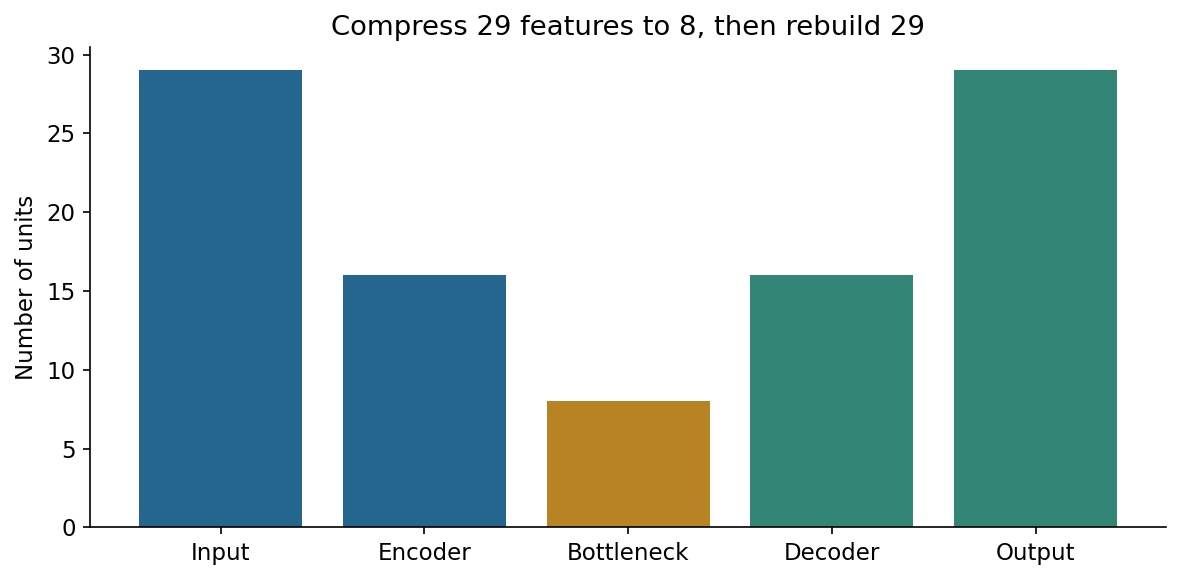

In [4]:
model = Autoencoder(8)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
print("Two-feature teaching example:", np.mean((np.array([1.1, 1.8])-np.array([1., 2.]))**2))
# Widths represent layer sizes, not learned transaction clusters.
plt.bar(range(5), [29, 16, 8, 16, 29], color=["#24668d", "#24668d", "#b88423", "#338575", "#338575"])
plt.xticks(range(5), ["Input", "Encoder", "Bottleneck", "Decoder", "Output"])
plt.ylabel("Number of units"); plt.title("Compress 29 features to 8, then rebuild 29")
show("03_architecture.png")

## Follow four transactions through the network
This is a **shape demonstration before training**, using four real legitimate inputs. It shows where compression happens. It does not measure model quality.

`(4, 29)` means four transactions with 29 features each. The bottleneck becomes `(4, 8)`; the output returns to `(4, 29)`. Real training uses batches of up to 1,024 rows. **No Class column enters the network.**

In [5]:
# Follow the dimensions; these untrained outputs are not anomaly scores.
example_inputs = torch.from_numpy(X_train[:4])
with torch.no_grad():
    example_encoded = model.encoder(example_inputs)
    example_rebuilt = model(example_inputs)
display(pd.DataFrame({
    "stage": ["Input", "Compressed", "Rebuilt"],
    "rows": [int(x.shape[0]) for x in [example_inputs, example_encoded, example_rebuilt]],
    "features_per_row": [int(x.shape[1]) for x in [example_inputs, example_encoded, example_rebuilt]]
}))
assert example_inputs.shape == (4, 29)
assert example_encoded.shape == (4, 8)
assert example_rebuilt.shape == (4, 29)
print("This shows the network dimensions. Weight training starts below.")

This shows the network dimensions. Weight training starts below.


,stage,rows,features_per_row
0,Input,4,29
1,Compressed,4,8
2,Rebuilt,4,29


## 2. The training loop in ordinary words
1. Take a batch of 1,024 legitimate rows. A **batch** is a small group used for one update.
2. Add small Gaussian noise (SD 0.10 in scaled units) to the input. Keep the clean row as the target.
3. Run the forward pass to get reconstructed values.
4. Compute mean squared error (MSE).
5. `backward()` computes gradients: how each weight affected the loss.
6. Adam uses those gradients to update the weights. Clear old gradients before each update.
7. After an **epoch** (one pass over training rows), check clean legitimate validation error.
8. Restore the best saved epoch. Stop after five epochs without enough improvement, or at 30 epochs.

The bottleneck limits copying capacity. Noise teaches recovery from small perturbations.
Weight decay discourages large weights. Early stopping limits unnecessary training.
Lower reconstruction loss does **not** automatically mean better fraud ranking.

In [6]:
def train_autoencoder(name, bottleneck=8, noise=0.10, seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = Autoencoder(bottleneck)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
    loss_function = nn.MSELoss()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_train)),
                        batch_size=1024, shuffle=True)
    best_loss, patience_count = float("inf"), 0
    history = []
    start = time.perf_counter()
    for epoch in range(1, 31):
        model.train()
        for (clean,) in loader:
            # Corrupt the INPUT only; the target is still the clean legitimate row.
            noisy = clean + noise * torch.randn_like(clean)
            optimizer.zero_grad()
            rebuilt = model(noisy)
            loss = loss_function(rebuilt, clean)
            loss.backward()
            optimizer.step()
        # Compare both losses in eval mode on CLEAN inputs, with no weight updates.
        train_mse = float(reconstruction_errors(model, X_train).mean())
        val_mse = float(reconstruction_errors(model, X_normal_validation).mean())
        assert np.isfinite(train_mse) and np.isfinite(val_mse)
        history.append({"epoch": epoch, "train_mse": train_mse, "normal_validation_mse": val_mse})
        print(f"{name}: epoch {epoch:02d}, train {train_mse:.4f}, validation {val_mse:.4f}")
        if val_mse < best_loss - 1e-4:
            best_loss, patience_count = val_mse, 0
            best_state, best_epoch = copy.deepcopy(model.state_dict()), epoch
        else:
            patience_count += 1
        if patience_count == 5:
            break
    torch.save(model.state_dict(), P2 / "models" / f"{name}_last.pt")
    model.load_state_dict(best_state)
    torch.save(best_state, P2 / "models" / f"{name}.pt")
    pd.DataFrame(history).to_csv(P2 / "results" / f"{name}_history.csv", index=False)
    settings = {"name": name, "bottleneck": bottleneck, "noise": noise, "seed": seed,
                "parameters": sum(p.numel() for p in model.parameters()),
                "best_epoch": best_epoch, "epochs_run": epoch, "best_normal_validation_mse": best_loss,
                "seconds": time.perf_counter()-start}
    return model, settings

## 3. Train a plain AE first, then our denoising AE
Only the noise changes, so this comparison isolates the denoising intervention.
Both have the same bottleneck, weight decay, rows, stopping rule and seed.
The main denoising model was fixed before seeing Phase 2 test results.

In [7]:
trained, runs = {}, []
for name, bottleneck, noise, seed in [
    ("plain_ae", 8, 0.0, 42),
    ("denoising_ae", 8, 0.10, 42),
]:
    trained[name], settings = train_autoencoder(name, bottleneck, noise, seed)
    runs.append(settings)
display(pd.DataFrame(runs).round(4))

plain_ae: epoch 01, train 0.7901, validation 1.0440
plain_ae: epoch 02, train 0.6732, validation 0.9436
plain_ae: epoch 03, train 0.6310, validation 0.9041
plain_ae: epoch 04, train 0.5827, validation 0.8590
plain_ae: epoch 05, train 0.5546, validation 0.8315
plain_ae: epoch 06, train 0.5317, validation 0.8146
plain_ae: epoch 07, train 0.5156, validation 0.8023
plain_ae: epoch 08, train 0.5047, validation 0.7914
plain_ae: epoch 09, train 0.4961, validation 0.7824
plain_ae: epoch 10, train 0.4897, validation 0.7767
plain_ae: epoch 11, train 0.4842, validation 0.7684
plain_ae: epoch 12, train 0.4790, validation 0.7637
plain_ae: epoch 13, train 0.4737, validation 0.7593
plain_ae: epoch 14, train 0.4697, validation 0.7519
plain_ae: epoch 15, train 0.4647, validation 0.7428
plain_ae: epoch 16, train 0.4603, validation 0.7372
plain_ae: epoch 17, train 0.4565, validation 0.7338
plain_ae: epoch 18, train 0.4538, validation 0.7356
plain_ae: epoch 19, train 0.4517, validation 0.7287
plain_ae: ep

,name,bottleneck,noise,seed,parameters,best_epoch,epochs_run,best_normal_validation_mse,seconds
0,plain_ae,8,0.0,42,1253,30,30,0.7119,9.6147
1,denoising_ae,8,0.1,42,1253,30,30,0.7130,8.9488


## 4. Ablations: change one setting at a time
The wider bottleneck changes 8 to 12. It tests the effect of compression and also changes parameter count.
The second seed changes only the random initialization and batch order; two seeds are a sensitivity check,
not a complete uncertainty estimate. Keep every run even if it performs worse.

In [8]:
for name, bottleneck, noise, seed in [
    ("wide_ae", 12, 0.10, 42),
    ("seed43_ae", 8, 0.10, 43),
]:
    trained[name], settings = train_autoencoder(name, bottleneck, noise, seed)
    runs.append(settings)
settings = {"architecture": [29,16,8,16,29], "optimizer": "Adam", "learning_rate": 0.001,
            "weight_decay": 1e-5, "batch_size": 1024, "max_epochs": 30,
            "patience": 5, "min_delta": 1e-4, "training_rows": len(X_train),
            "validation_normal_rows": len(X_normal_validation),
            "device": "cpu", "selection": "normal validation MSE only",
            "main_model": "denoising_ae", "runs": runs, "torch_version": str(torch.__version__)}
(P2 / "results/training_settings.json").write_text(json.dumps(settings, indent=2))
display(pd.DataFrame(runs).round(4))

wide_ae: epoch 01, train 0.7472, validation 0.9740
wide_ae: epoch 02, train 0.6018, validation 0.8442
wide_ae: epoch 03, train 0.5408, validation 0.7933
wide_ae: epoch 04, train 0.4995, validation 0.7469
wide_ae: epoch 05, train 0.4481, validation 0.6839
wide_ae: epoch 06, train 0.4283, validation 0.6646
wide_ae: epoch 07, train 0.4178, validation 0.6611
wide_ae: epoch 08, train 0.4132, validation 0.6613
wide_ae: epoch 09, train 0.4098, validation 0.6634
wide_ae: epoch 10, train 0.4081, validation 0.6599
wide_ae: epoch 11, train 0.4065, validation 0.6611
wide_ae: epoch 12, train 0.4051, validation 0.6650
wide_ae: epoch 13, train 0.4039, validation 0.6673
wide_ae: epoch 14, train 0.4034, validation 0.6652
wide_ae: epoch 15, train 0.4020, validation 0.6674
seed43_ae: epoch 01, train 0.8155, validation 1.0367
seed43_ae: epoch 02, train 0.6730, validation 0.9337
seed43_ae: epoch 03, train 0.5994, validation 0.8559
seed43_ae: epoch 04, train 0.5537, validation 0.8158
seed43_ae: epoch 05, tr

,name,bottleneck,noise,seed,parameters,best_epoch,epochs_run,best_normal_validation_mse,seconds
0,plain_ae,8,0.0,42,1253,30,30,0.7119,9.6147
1,denoising_ae,8,0.1,42,1253,30,30,0.7130,8.9488
2,wide_ae,12,0.1,42,1385,10,15,0.6599,4.4506
3,seed43_ae,8,0.1,43,1253,28,30,0.6845,8.9986


## 5. Visual: is the model learning?
Both curves below use clean inputs in evaluation mode, so noise does not inflate the training curve.
Validation is a later time period, so a loss gap can reflect changing data as well as overfitting.
The vertical line marks the restored epoch. Read the observed curves rather than assuming early stopping fired.

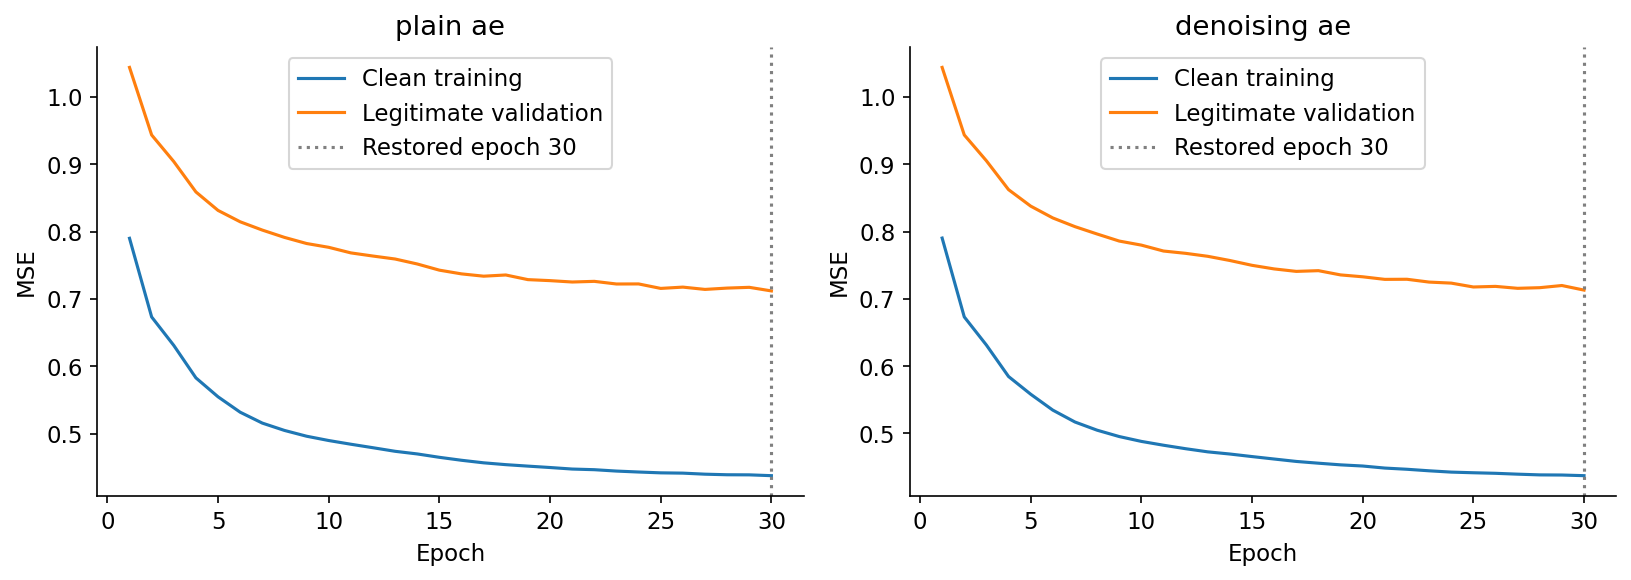

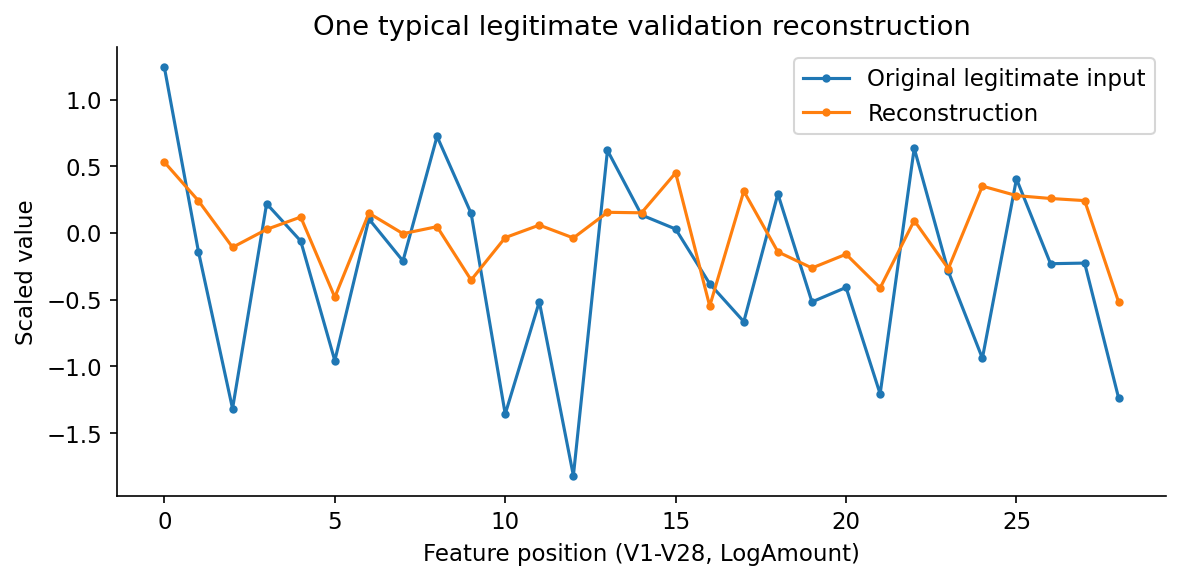

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, ["plain_ae", "denoising_ae"]):
    h = pd.read_csv(P2 / "results" / f"{name}_history.csv")
    best = next(r["best_epoch"] for r in runs if r["name"] == name)
    ax.plot(h.epoch, h.train_mse, label="Clean training")
    ax.plot(h.epoch, h.normal_validation_mse, label="Legitimate validation")
    ax.axvline(best, color="gray", linestyle=":", label=f"Restored epoch {best}")
    ax.set_title(name.replace("_", " ")); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE"); ax.legend()
show("04_learning.png")
# A normal-validation example, selected without looking at any test labels.
normal_scores = reconstruction_errors(trained["denoising_ae"], X_normal_validation)
i = int(np.argsort(normal_scores)[len(normal_scores)//2])
x = torch.from_numpy(X_normal_validation[i:i+1])
with torch.no_grad(): rebuilt = trained["denoising_ae"](x).numpy()[0]
plt.plot(x.numpy()[0], "o-", label="Original legitimate input", markersize=3)
plt.plot(rebuilt, "o-", label="Reconstruction", markersize=3)
plt.xlabel("Feature position (V1-V28, LogAmount)"); plt.ylabel("Scaled value")
plt.title("One typical legitimate validation reconstruction"); plt.legend()
show("05_reconstruction.png")

**Say in the viva:** Training learns to rebuild normal data. The model sees no fraud examples during weight
updates. The bottleneck and noise make a simple copy less easy, but they cannot guarantee that fraud has high error.

**Reading:** Sakurada & Yairi (2014), DOI https://doi.org/10.1145/2689746.2689747, is the assignment's
suggested AE anomaly-detection paper. Vincent et al. (2010), https://www.jmlr.org/papers/v11/vincent10a.html,
explains learning from corrupted inputs with clean targets. Our small network is a course experiment,
not a reproduction of either paper. PyTorch references:
https://docs.pytorch.org/docs/stable/generated/torch.nn.MSELoss.html and
https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html.